# Lab 28 — Multimodal SecureLife: Vision + Text RAG

## A Motor Insurance Claims Agent That Sees and Reads

**Domain:** Insurance (SecureLife — extends Module 6) · **Modalities:** Vision (GPT-4o) + Text RAG (FAISS over policy docs)

The SecureLife agent system you built in Module 6 reviews claims using only structured data (DB queries + 8 SQL tools). But the **real intake** at SecureLife isn't structured: customers upload **photos of vehicle damage** along with their text claim, and adjusters spend hours classifying what they see.

Today we add the missing modality. The agent will look at a damage photo, retrieve the relevant clauses from the customer's policy, cross-check against the existing claim record, and produce a coverage decision — all in one LangGraph pipeline.

## The Business Problem at SecureLife

A typical motor claim arrives like this:

> "Hi, I had a front-end collision at a traffic light on June 14. Other driver admitted fault. Repair estimate is **₹4,35,957**. Attached: photos of the damage. My policy is `POL-2024-0018` (SecureLife Motor Comprehensive). Please process under claim **CLM-2025-0001**."

Today's manual process — adjuster reviews photo, looks up policy, cross-checks the DB claim record — takes **30–45 min per claim**. SecureLife handles **~3,000 claims/month**.

We're going to build the agent version: **photo + policy → coverage decision** in seconds, with the same structured output the adjuster would produce.

## What's NEW in Lab 28 (vs the rest of the SecureLife labs)

> - **NEW:** Vision modality — `gpt-4o` analyses vehicle damage photos via the `image_url` content block API
> - **NEW:** Text RAG — FAISS vector store over the **SecureLife Motor Comprehensive policy document** so the agent grounds decisions in citable policy clauses
> - **NEW:** Multimodal LangGraph — 3 nodes that fan in vision + RAG findings + DB record, then synthesise a coverage decision
> - **NEW:** Fraud signal — the agent compares the **photo's damage estimate** against the **customer's claimed amount** and flags significant mismatches (a real-world fraud indicator)
> - **Inherits:** SecureLife claims DB schema if available (graceful fallback to inline mock claim)
> - **Time split:** ~60% vision + RAG + graph, ~40% setup and sample data

**Prereq:** None — the lab is self-contained. (If you have `/content/SecureLife_claims.db` from the Module 6 Setup notebook, it'll use real claim records; otherwise it uses a built-in mock.)

## Architecture

```
            Customer submits:
              - claim_id        (e.g. CLM-2025-0001)
              - photo bytes / URL  (vehicle damage)
                       │
                       ▼
            ┌───────────────────────────────────┐
            │  Multimodal LangGraph             │
            │                                    │
            │   vision_node    rag_node          │
            │   (gpt-4o)      (FAISS over        │
            │   • damage type   policy doc)      │
            │   • severity 1-10                  │
            │   • est. ₹ repair                   │
            │   • parts affected                  │
            │                                    │
            │              │   │                 │
            │              ▼   ▼                 │
            │      ┌──────────────────┐          │
            │      │ synthesize_node  │          │
            │      │ (gpt-4.1-mini)   │          │
            │      │ - cross-check    │          │
            │      │   photo vs claim │          │
            │      │ - cite policy    │          │
            │      │ - APPROVE/REVIEW/│          │
            │      │   REJECT         │          │
            │      └──────────────────┘          │
            └────────────┬──────────────────────┘
                         ▼
              Structured Decision:
              { decision: "APPROVE" | "REVIEW" | "REJECT",
                damage_severity: 1-10,
                estimated_repair_inr: int,
                claimed_amount_inr: int,
                fraud_signal: bool,
                policy_citations: [...],
                reasoning: "..." }
```

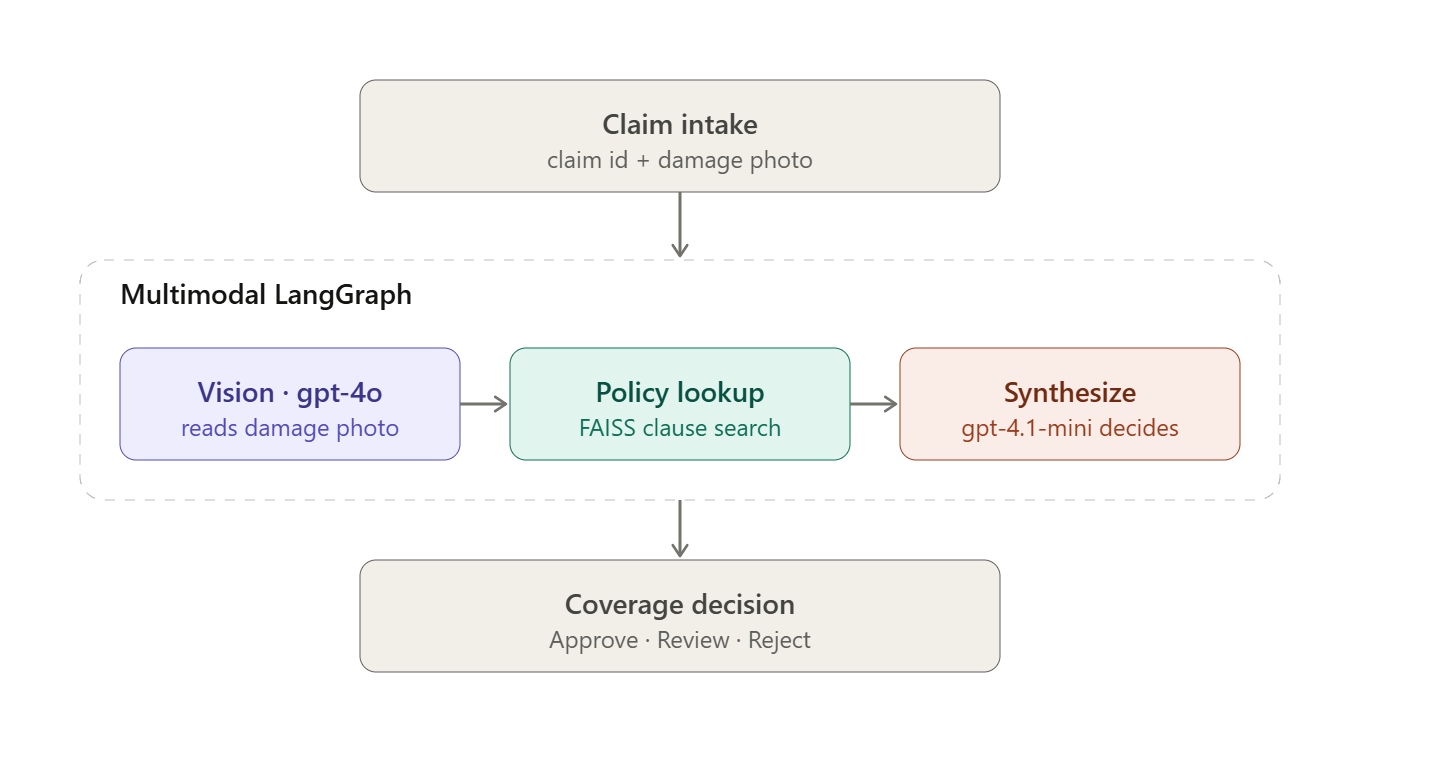

## How to Use This Guide (Read Me First)

This notebook is a **step-by-step build**. By the end you will have a working AI agent that looks at a photo of a damaged car, reads the relevant insurance policy, checks the claim record, and produces a coverage decision — all automatically.

You do **not** need to be an AI expert. Each step below contains three things:

1. A short note on **what you are about to do and why**.
2. A **code cell** with a comment on every part, so you can see what each line is for.
3. A plain-English **"What just happened"** explanation after the code runs.

### The end-to-end journey (7 steps)

| Step | Section | What you build | Why it matters |
|------|---------|----------------|----------------|
| 1 | Setup | Install libraries + load your OpenAI key | Nothing runs without this |
| 2 | Sample data | A claim record + 3 damage photos | The inputs the agent will judge |
| 3 | Vision tool | GPT-4o that *looks* at a photo and returns structured data | This is the "eyes" of the agent |
| 4 | Text RAG tool | A searchable index of the insurance policy | This is the "rulebook" the agent cites |
| 5 | The agent | A 3-step LangGraph pipeline that combines everything | This is the "brain" that decides |
| 6 | Run it | Feed 3 photos through the agent | See the decisions and the fraud check in action |
| 7 | Recap | Production path + key takeaways | How this becomes a real system |

### One mental model to keep in your head

> **Vision tells us *what is broken*. RAG tells us *what the policy covers*. The claim record tells us *what the customer asked for*. The agent cross-checks all three and decides: APPROVE, REVIEW, or REJECT.**

Run the cells **top to bottom, in order** — each step depends on the ones before it. Ready? Start with Step 1.

## Section 1 — Setup

**What you'll do in this step:** install the Python libraries the lab needs, then load your OpenAI API key so the notebook can call GPT-4o.

There are two code cells here. The first installs packages (run once). The second imports everything and finds your API key automatically — whether you're on Google Colab or running locally.

In [8]:
# %%capture hides the long, noisy pip-install log so the notebook stays tidy.
# (Remove this line if a package fails to install and you want to see the error.)
%%capture
# !pip install -q "langchain>=1.0" "langchain-openai>=0.2" "langgraph>=0.2" "langchain-community>=0.3" "faiss-cpu>=1.7" "pillow>=10" "pydantic>=2" "nest-asyncio" "python-dotenv"
# Install every library this lab uses, all in one line:
#   langchain / langchain-openai  -> talk to OpenAI models (incl. GPT-4o vision)
#   langgraph                     -> wire the agent steps into a pipeline (graph)
#   langchain-community + faiss-cpu-> build the searchable policy index (RAG)
#   pillow                        -> draw / read the sample damage images
#   pydantic                      -> force the model to return clean structured data
#   nest-asyncio                  -> let async code run inside a notebook
!pip install -q langchain langchain-openai langgraph langchain-community faiss-cpu pillow pydantic nest-asyncio


**What just happened:** all required libraries are now installed. The commented-out line above (`# !pip install ... "langchain>=1.0" ...`) is just a *pinned-version* alternative — useful if you ever need exact versions for reproducibility, but the active line is enough for the lab.

In [9]:
# --- Imports + API key (Colab/local detection) ---
# Standard-library tools we'll need throughout the lab:
#   os/sys  -> environment variables & system settings
#   json    -> turn Python objects into text for the model and back
#   base64  -> encode an image as text so it can travel inside an API call
#   sqlite3 -> read the optional SecureLife claims database
import os, sys, json, base64, io, sqlite3
from typing import TypedDict, Optional, List
from io import BytesIO

try:
    # Make sure the notebook can print the rupee sign and other symbols
    # without crashing on Windows / older terminals.
    sys.stdout.reconfigure(encoding="utf-8")
except Exception:
    pass

try:
    # First choice: if we're on Google Colab, read the key from Colab 'Secrets'
    # (the key icon in the left sidebar). This keeps the key out of the notebook.
    from google.colab import userdata
    os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
    ENV = "Colab"
except ImportError:
    try:
        # Not on Colab? Then we're probably running locally. Try to load the key
        # from a local .env file (a file that holds OPENAI_API_KEY=sk-...).
        from dotenv import load_dotenv
        load_dotenv()
    except ImportError:
        pass
# If we still don't have a key, stop now with a clear message instead of
# failing mysteriously later when we call the model.
    if "OPENAI_API_KEY" not in os.environ:
        raise RuntimeError(
            "OPENAI_API_KEY not found. Set it via Colab Secrets or .env file."
        )
    ENV = "Local"

# LangChain/LangGraph use async under the hood; this patch lets that run
# smoothly inside a Jupyter/Colab notebook.
import nest_asyncio
nest_asyncio.apply()

# Confirm setup worked and tell us which environment was detected.
print(f"✓ Setup complete — environment: {ENV}")


✓ Setup complete — environment: Colab


**What just happened:** the notebook imported its tools and located your OpenAI API key. The `try/except` blocks are just *auto-detection* — they let the **same** notebook run unchanged on Colab (key from Secrets) or on your own machine (key from a `.env` file). If you saw `✓ Setup complete`, you're ready for Step 2. If you saw the `OPENAI_API_KEY not found` error, add your key and re-run this cell.

## Section 2 — Sample Claim Data + Damage Photos

We need two things to feed the agent:

1. **A claim record** — pulled from SecureLife DB if available, otherwise a built-in mock
2. **A vehicle damage photo** — we generate **3 synthetic damage images** with Pillow so the lab runs everywhere with no external image dependencies

> The notebook works even without the SecureLife DB file. If you have `Lab_M6_Setup_SecureLife_DB.ipynb` results on disk, it'll use the real claim; otherwise it falls back to a representative mock claim for CLM-2025-0001 (motor comprehensive, ₹4.35L claim).

**What you'll do in this step:** assemble the two inputs the agent needs to judge a claim — **(a)** a claim record (who, which policy, how much they're asking for) and **(b)** vehicle damage photos.

There are four code cells in this step:
- Cell 1: load the claim record (from the real database if present, otherwise a built-in mock).
- Cell 2: *generate* 3 synthetic damage drawings with Pillow — so the lab runs anywhere with no image files needed.
- Cell 3: *override* those drawings with real image files if you have them on disk.
- Cell 4: display whichever images are loaded, so you can see what GPT-4o will analyse.

In [10]:
# --- Load the SecureLife claim record (DB if present, else mock) ---

# A representative fake claim used when no real database is available.
# This is the customer's side of the story: what they say happened and the
# amount they're claiming (₹4,35,957). The agent will test this against the photo.
MOCK_CLAIM = {
    "claim_id":      "CLM-2025-0001",
    "diagnosis":     "Front-end collision damage",
    "claim_amount":  435957,
    "status":        "UNDER_REVIEW",
    "category":      "SUSPICIOUS",
    "fraud_score":   0.66,
    "admit_date":    "2025-06-19",
    "discharge_date":"2025-06-28",
    "submitted_at":  "2025-06-30T00:00:00",
    "customer_id":   "CUST-0001",
    "full_name":     "Rajesh Sharma",
    "city":          "Bengaluru",
    "policy_id":     "POL-2024-0018",
    "policy_type":   "MOTOR",
    "sum_insured":   500000,
    "product_name":  "SecureLife Motor Comprehensive",
}

# Try to load a REAL claim from the SecureLife database; if the .db file isn't
# found in any of the usual locations, quietly fall back to MOCK_CLAIM above.
# This 'graceful fallback' is why the lab works for everyone.
def load_claim(claim_id: str) -> dict:
    """Try the SecureLife DB; fall back to inline mock if unavailable."""
    # Check several common locations where the DB file might live.
    for db_path in ["/content/SecureLife_claims.db", "SecureLife_claims.db",
                     "../SecureLife_claims.db", "../../SecureLife_claims.db"]:
        if os.path.exists(db_path):
            # Open the database and run a JOIN to pull the claim plus the linked
            # customer and policy details in one query.
            conn = sqlite3.connect(db_path)
            conn.row_factory = sqlite3.Row
            rows = conn.execute(
                """SELECT c.*, cu.full_name, cu.city,
                          p.policy_id, p.policy_type, p.sum_insured, p.product_name
                   FROM claims c
                   JOIN customers cu ON c.customer_id = cu.customer_id
                   JOIN policies  p  ON c.policy_id   = p.policy_id
                   WHERE c.claim_id = ?""", (claim_id,)).fetchall()
            conn.close()
            if rows:
                print(f"  → loaded {claim_id} from {db_path}")
                return dict(rows[0])
    # No database found anywhere -> use the built-in mock claim instead.
    print(f"  → DB not found; using MOCK_CLAIM for {claim_id}")
    return MOCK_CLAIM

# Load claim CLM-2025-0001 and print a quick human-readable summary so we can
# eyeball the customer, policy, and claimed amount before going further.
claim_record = load_claim("CLM-2025-0001")
print(f"✓ Claim record:")
print(f"  customer:  {claim_record.get('full_name')} ({claim_record.get('city')})")
print(f"  policy:    {claim_record.get('product_name')}")
print(f"  amount:    ₹{claim_record.get('claim_amount'):,}")
print(f"  diagnosis: {claim_record.get('diagnosis')}")


  → loaded CLM-2025-0001 from /content/SecureLife_claims.db
✓ Claim record:
  customer:  Rajesh Sharma (Bengaluru)
  policy:    SecureLife Motor Comprehensive
  amount:    ₹435,957
  diagnosis: Front-end collision damage


**What just happened:** you now have a `claim_record` dictionary in memory. The key field to remember is **`claim_amount` = ₹4,35,957** — later, the agent compares this against the repair cost it estimates *from the photo*. A big mismatch is the core fraud signal of this lab.

Note the JOIN in the SQL: a claim alone isn't enough; the agent also needs the **customer** (name, city) and the **policy** (product, sum insured) to make a fair decision, so all three tables are pulled together.

In [11]:
# --- Generate 3 synthetic vehicle damage images with Pillow ---
# Pillow is a drawing library. We use it to PAINT simple car pictures so the
# lab needs no external image files. (Step 2, cell 3 lets you swap in real photos.)
from PIL import Image, ImageDraw, ImageFont

# Helper: draws a plain side-view car (body, cabin, windows, wheels).
def draw_vehicle(draw: ImageDraw.ImageDraw) -> None:
    """Draw a simple side-view car silhouette."""
    # Body
    draw.rectangle([100, 220, 540, 360], fill="steelblue", outline="black", width=3)
    # Cabin
    draw.polygon([(180, 220), (220, 150), (430, 150), (470, 220)],
                 fill="steelblue", outline="black", width=3)
    # Windows
    draw.polygon([(195, 215), (230, 160), (320, 160), (320, 215)],
                 fill="lightblue", outline="black", width=2)
    draw.polygon([(330, 215), (330, 160), (420, 160), (455, 215)],
                 fill="lightblue", outline="black", width=2)
    # Wheels
    draw.ellipse([130, 340, 210, 420], fill="black")
    draw.ellipse([430, 340, 510, 420], fill="black")
    draw.ellipse([150, 360, 190, 400], fill="dimgray")
    draw.ellipse([450, 360, 490, 400], fill="dimgray")

# Draw the car, then add damage on top depending on the scenario, and return
# the finished picture as raw PNG bytes (the format the vision API expects).
def make_damage_image(damage_type: str) -> bytes:
    """Return PNG bytes for a synthetic vehicle damage scenario."""
    img = Image.new("RGB", (640, 480), color="white")
    draw = ImageDraw.Draw(img)
    draw_vehicle(draw)

    # Scenario 1: a single deep gash on the front -> looks moderate.
    if damage_type == "front_collision":
        # Deep gash in front bumper area
        draw.polygon([(100, 230), (180, 280), (140, 350), (100, 330)],
                     fill="darkred", outline="black", width=2)
        draw.polygon([(120, 250), (160, 290), (135, 340)],
                     fill="black", outline=None)
        draw.line([(140, 260), (180, 320)], fill="white", width=2)
        draw.text((40, 30), "FRONT-END COLLISION", fill="darkred")
    # Scenario 2: light surface scratches -> looks minor / cheap to fix.
    elif damage_type == "side_scratch":
        # Multiple horizontal scratches on side panel
        for y in range(235, 340, 8):
            draw.line([(230, y), (430, y + 3)], fill="dimgray", width=1)
        # One deep scratch
        draw.line([(230, 285), (430, 295)], fill="black", width=3)
        draw.text((40, 30), "SIDE PANEL SCRATCHES", fill="black")
    # Scenario 3: damage everywhere + caved roof + cracked glass -> looks severe.
    elif damage_type == "total_loss":
        # Multiple severe damage areas
        draw.polygon([(100, 220), (190, 270), (140, 360), (100, 340)],
                     fill="darkred", outline="black", width=2)
        draw.polygon([(440, 220), (540, 280), (530, 360), (450, 320)],
                     fill="darkred", outline="black", width=2)
        # Caved-in roof
        draw.polygon([(220, 175), (280, 145), (350, 165), (430, 180), (430, 200), (220, 200)],
                     fill="darkgray", outline="black", width=2)
        # Cracked windshield
        for start, end in [((230, 175), (310, 210)), ((310, 210), (370, 175)),
                            ((230, 200), (350, 165)), ((290, 210), (410, 175))]:
            draw.line([start, end], fill="white", width=2)
        draw.text((40, 30), "TOTAL LOSS — SEVERE DAMAGE", fill="darkred")

    # Save the picture into an in-memory buffer and hand back the PNG bytes
    # (no file is written to disk).
    buf = BytesIO()
    img.save(buf, format="PNG")
    return buf.getvalue()

# Generate all 3 sample images
# Build a dictionary of all three damage pictures, keyed by scenario name.
# This SAMPLE_IMAGES dict is what the rest of the lab feeds to the agent.
SAMPLE_IMAGES = {
    "front_collision": make_damage_image("front_collision"),
    "side_scratch":    make_damage_image("side_scratch"),
    "total_loss":      make_damage_image("total_loss"),
}
print(f"✓ Generated {len(SAMPLE_IMAGES)} synthetic damage images:")
for k, v in SAMPLE_IMAGES.items():
    print(f"  • {k:18s}  {len(v):>6d} bytes")


✓ Generated 3 synthetic damage images:
  • front_collision       5525 bytes
  • side_scratch          5179 bytes
  • total_loss            7278 bytes


**What just happened:** you created `SAMPLE_IMAGES` — a dictionary holding three pictures (`front_collision`, `side_scratch`, `total_loss`) as PNG bytes. They're simple drawings, but that's fine: GPT-4o treats a drawing and a real photo the same way, so the *pipeline* you build is identical to a production one. The printout shows each image's size in bytes as a sanity check that they were created.

In [12]:
# import the images from /content
# OPTIONAL OVERRIDE: if you have real photos on disk (e.g. uploaded to Colab's
# /content folder), name them here. These three files replace the drawings above.
img1 = "backside-damage.png"
img2 = "side-damage.jpg"
img3 = "vehicle-damage.jpg"

# convert these images into bytes
# Read each image file in binary mode ('rb') and keep its raw bytes,
# exactly the format the vision tool needs.
with open(img1, "rb") as f:
    img1_bytes = f.read()

with open(img2, "rb") as f:
    img2_bytes = f.read()

with open(img3, "rb") as f:
    img3_bytes = f.read()

# Generate all 3 sample images
# Re-build SAMPLE_IMAGES using the REAL photos instead of the drawings.
# Mapping note: vehicle-damage.jpg -> front_collision, side-damage.jpg ->
# side_scratch, backside-damage.png -> total_loss.
SAMPLE_IMAGES = {
    "front_collision": img3_bytes,
    "side_scratch":    img2_bytes,
    "total_loss":      img1_bytes,
}

# Print each image name and byte size to confirm the real files loaded.
for k, v in SAMPLE_IMAGES.items():
    print(f"  • {k:18s}  {len(v):>6d} bytes")

FileNotFoundError: [Errno 2] No such file or directory: 'backside-damage.png'

**What just happened:** this cell *overrides* the synthetic drawings with real image files (`vehicle-damage.jpg`, `side-damage.jpg`, `backside-damage.png`).

Important: this cell only works if those three files are actually present (for example, uploaded into Colab's `/content` folder). **If you don't have them, skip this cell** and keep the synthetic images from the previous cell — everything downstream still works. The keys (`front_collision`, `side_scratch`, `total_loss`) stay the same either way, so the rest of the notebook doesn't care which images you used.


--- FRONT COLLISION ---


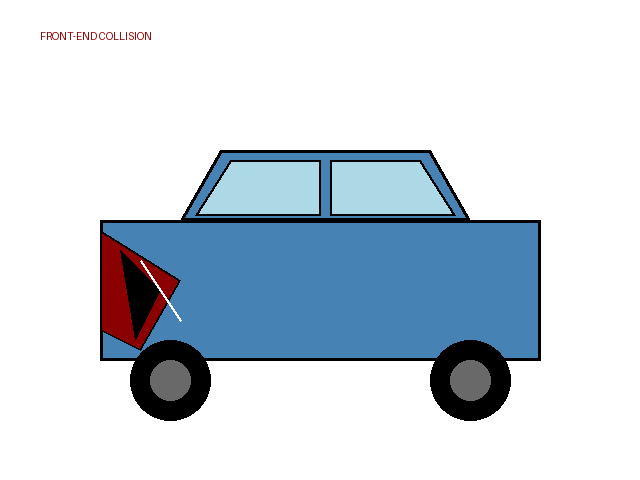


--- SIDE SCRATCH ---


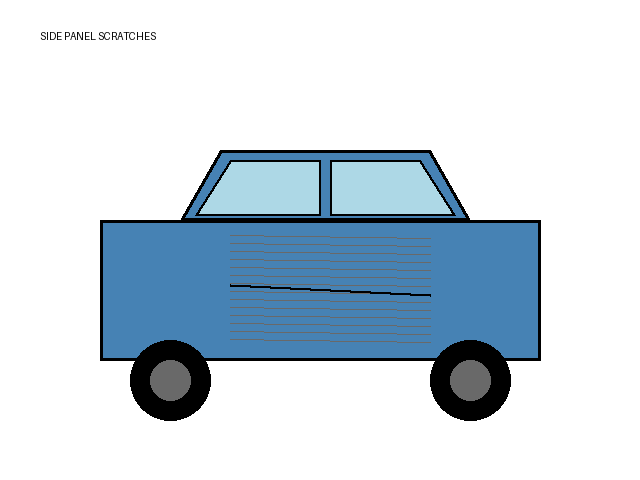


--- TOTAL LOSS ---


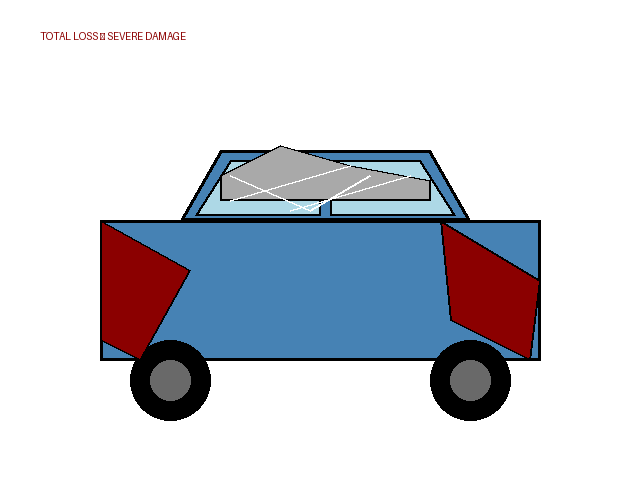


(Synthetic images — they look schematic, but GPT-4o handles real photos identically.
 To use real photos, swap the `image_url` content block in the next section.)


In [13]:
# --- Display the sample images inline so you can see what GPT-4o will analyse ---
# IPython display helpers let us show pictures directly inside the notebook.
from IPython.display import Image as IPyImage, display
import textwrap

# Loop over the three scenarios and render each image inline so you can
# see exactly what the vision model will be looking at.
for damage_type, png_bytes in SAMPLE_IMAGES.items():
    print(f"\n--- {damage_type.replace('_', ' ').upper()} ---")
    display(IPyImage(data=png_bytes, format="png", width=320))

print("\n(Synthetic images — they look schematic, but GPT-4o handles real photos identically.")
print(" To use real photos, swap the `image_url` content block in the next section.)")


**What just happened:** you can now *see* the three inputs. Look at them with an adjuster's eye and predict the outcome yourself: the front collision looks moderate, the scratches look cheap, the total-loss image looks severe. Keep those gut predictions in mind — in Step 6 you'll check whether the agent reasons the same way you did.

## Section 3 — Vision Tool (GPT-4o)

The vision tool uses **`gpt-4o`** — OpenAI's flagship multimodal model — through LangChain's `ChatOpenAI`. The trick is the **content block format**: instead of a plain string, the user message becomes a list of blocks, each either text or `image_url`.

### Two ways to pass an image

```python
# 1. As a base64 data URL (what we'll use — keeps everything offline-safe)
{"type": "image_url",
 "image_url": {"url": "data:image/png;base64,<base64string>"}}

# 2. As a public HTTPS URL (no upload, GPT-4o fetches it directly)
{"type": "image_url",
 "image_url": {"url": "https://example.com/damage.jpg"}}
```

The structured output uses Pydantic to force GPT-4o to return JSON with the exact fields we need.

**What you'll do in this step:** build the agent's **eyes** — a function that sends a photo to GPT-4o and gets back *structured* data (damage type, severity 1-10, estimated repair cost, parts affected, confidence).

The key idea (explained in the section text above): an image is passed to the model as an **`image_url` content block**. The other key idea is **structured output** — instead of a chatty paragraph, we force the model to fill in a fixed form (a Pydantic schema) so the answer is machine-usable.

In [14]:
# --- Define the vision tool ---
# ChatOpenAI is LangChain's wrapper for OpenAI chat models.
# Pydantic's BaseModel/Field let us DEFINE the exact shape of the answer we want.
from langchain_openai import ChatOpenAI
from pydantic import BaseModel, Field

# gpt-4o is OpenAI's multimodal model (it can read images).
# temperature=0 -> deterministic, no creative guessing. We want consistent
# assessments, not variety.
vision_llm = ChatOpenAI(model="gpt-4o", temperature=0)

# THIS IS THE 'FORM' the model must fill in. Each Field's description is an
# instruction to the model about what that field means. Pydantic also validates
# the result (e.g. severity must be an int between 1 and 10).
class DamageAssessment(BaseModel):
    """Structured output from the vision model."""
    damage_type: str = Field(description=
        "Short label: front_collision | rear_collision | side_panel_scratch | "
        "total_loss | minor_dent | windshield_crack | flood_damage | other")
    severity: int = Field(ge=1, le=10, description=
        "1=cosmetic only, 5=moderate panel work, 10=total loss / unrepairable")
    estimated_repair_inr: int = Field(description=
        "Indian Rupees estimate based on the visible damage. Use realistic ranges: "
        "minor ₹5K-₹30K, moderate ₹30K-₹2L, severe ₹2L-₹6L, total loss > ₹5L")
    parts_affected: List[str] = Field(description=
        "Affected vehicle components, e.g. ['front bumper', 'hood', 'left headlight']")
    confidence: float = Field(ge=0.0, le=1.0, description=
        "How confident the model is in its assessment (1.0 = very confident)")
    summary: str = Field(description=
        "One-sentence description of what's visible in the photo.")

# .with_structured_output(Schema) is the magic line: it binds the model to the
# form above, so .invoke() returns a clean DamageAssessment object, not free text.
vision_chain = vision_llm.with_structured_output(DamageAssessment)


# The reusable vision tool. Give it image bytes; get back a DamageAssessment.
def analyse_damage_photo(image_bytes: bytes) -> DamageAssessment:
    """Analyse a damage photo and return structured DamageAssessment."""
    # Step A: turn the raw image bytes into a base64 text string, then wrap it as a
    # 'data URL' (data:image/png;base64,...). This lets the image travel inside JSON.
    b64 = base64.b64encode(image_bytes).decode("ascii")
    data_url = f"data:image/png;base64,{b64}"

    # Step B: build a single user message that mixes TWO content blocks --
    # a text instruction AND the image. This list-of-blocks format is how you
    # send images to GPT-4o.
    message = {
        "role": "user",
        "content": [
            {"type": "text", "text":
                "You are SecureLife's vehicle damage assessor. Look at this photo "
                "of a damaged vehicle and produce a structured assessment. "
                "Be realistic about INR repair cost estimates for the Indian market."},
            {"type": "image_url", "image_url": {"url": data_url}},
        ],
    }
    # Step C: send it and return the filled-in DamageAssessment form.
    return vision_chain.invoke([message])

print("✓ Vision tool defined: analyse_damage_photo(image_bytes) -> DamageAssessment")


✓ Vision tool defined: analyse_damage_photo(image_bytes) -> DamageAssessment


**What just happened:** you defined `analyse_damage_photo(image_bytes)`. Walk through the three labelled steps inside it:

- **Step A — encode:** images can't travel as raw bytes inside a JSON API call, so they're converted to base64 text and wrapped as a `data:image/png;base64,...` URL.
- **Step B — build a mixed message:** the `content` is a **list** of two blocks: one `text` (the instruction) and one `image_url` (the picture). This list-of-blocks pattern is the *entire* trick to "multimodal" — there's no separate vision API.
- **Step C — invoke:** because of `with_structured_output(DamageAssessment)`, the reply comes back as a validated object with fields like `.severity` and `.estimated_repair_inr`, ready to use in code.

This "fill in a form, don't write a paragraph" approach is what makes the output reliable enough to drive an automated decision later.

In [15]:
# --- Test the vision tool on the front-collision image ---
# Quick sanity check: run the vision tool on the front-collision image...
result = analyse_damage_photo(SAMPLE_IMAGES["front_collision"])

# ...and print each field of the structured result in a readable way.
print("VISION OUTPUT (front_collision):")
print(f"  damage_type:           {result.damage_type}")
print(f"  severity:              {result.severity}/10")
print(f"  estimated_repair_inr:  ₹{result.estimated_repair_inr:,}")
print(f"  parts_affected:        {result.parts_affected}")
print(f"  confidence:            {result.confidence:.2f}")
print(f"  summary:               {result.summary}")


VISION OUTPUT (front_collision):
  damage_type:           front_collision
  severity:              5/10
  estimated_repair_inr:  ₹150,000
  parts_affected:        ['front bumper', 'hood', 'left headlight']
  confidence:            0.90
  summary:               The vehicle has a front-end collision with damage to the bumper, hood, and left headlight.


**What just happened:** you tested the eyes on one image and printed the structured result. Notice you can access fields with normal dot-notation (`result.severity`, `result.estimated_repair_inr`) — that's the payoff of structured output. The `estimated_repair_inr` value here is the number the agent will later compare against the customer's claimed amount.

## Section 4 — Text Tool: RAG over the SecureLife Motor Policy

The vision tool tells us **what's broken**. The RAG tool tells us **what the policy covers**.

We index the **SecureLife Motor Comprehensive Policy** document (excerpted below — a synthetic but realistic policy covering own-damage, third-party, exclusions, and claim procedure) into a FAISS vector store. The agent will query it semantically — e.g. "Is collision damage covered?" or "What's the deductible for own-damage claims?".

**What you'll do in this step:** build the agent's **rulebook** using RAG (Retrieval-Augmented Generation).

In plain terms: we take the insurance policy, break it into clauses, and store them in a **vector store** (FAISS) that supports *meaning-based* search. Later the agent can ask a question like *"Is collision damage covered?"* and instantly pull back the most relevant clauses — so its decision is grounded in the actual policy, with citations, instead of made up.

Three code cells: (1) the policy text, (2) build the searchable index, (3) wrap it in a simple `policy_lookup()` tool.

In [16]:
# --- The SecureLife Motor Comprehensive Policy document (10 clauses) ---
# The full SecureLife Motor policy, broken into 10 self-contained clauses.
# Each KEY is a citable clause ID (e.g. 'FR-001_FraudIndicators') and each VALUE
# is the clause text. Splitting into clauses is what makes precise retrieval +
# citation possible. Watch FR-001 (fraud) and OD-002 (total loss) -- the agent
# leans on these later.
POLICY_CLAUSES = {
    "OD-001_OwnDamageCoverage": (
        "Section A — Own Damage Coverage. SecureLife Motor Comprehensive policy covers "
        "loss or damage to the insured vehicle arising from accident, collision, fire, "
        "theft, malicious acts, natural calamities (flood, earthquake, cyclone), and "
        "transit damage. The maximum coverage equals the Insured's Declared Value (IDV) "
        "as stated on the policy schedule, less applicable depreciation and deductibles."
    ),
    "OD-002_TotalLossDefinition": (
        "A vehicle is declared a constructive total loss (CTL) when the cost of repair "
        "exceeds 75% of the IDV at the time of the accident. In CTL cases, the company "
        "settles the IDV in full less the policyholder's compulsory deductible. The "
        "salvage rights transfer to SecureLife unless otherwise agreed."
    ),
    "OD-003_Deductibles": (
        "Compulsory deductibles apply to every own-damage claim: ₹1,000 for vehicles "
        "below 1500cc engine capacity, ₹2,000 for vehicles 1500cc and above. Voluntary "
        "deductible discounts may apply if elected at policy inception. The deductible "
        "is reduced from the assessed repair cost before settlement."
    ),
    "TP-001_ThirdPartyLiability": (
        "Section B — Third-Party Liability. The policy covers the insured's legal "
        "liability for death or bodily injury to a third party and for property damage, "
        "subject to statutory limits set by the Motor Vehicles Act. Third-party "
        "property damage cover is limited to ₹7,50,000 unless extended."
    ),
    "CL-001_ClaimProcedure": (
        "Section C — Claim Procedure. The insured must notify SecureLife within 48 "
        "hours of the incident. Required documents: filled claim form, original police "
        "FIR (for theft, third-party injury, or accident with damages exceeding "
        "₹50,000), driving licence copy, registration certificate (RC), repair estimate "
        "from an authorised garage, post-repair invoice, and photographs of the damage."
    ),
    "CL-002_AuthorisedGarages": (
        "SecureLife operates a cashless repair facility through its network of authorised "
        "garages. The insured may choose cashless settlement (no upfront payment) at any "
        "network garage, or reimbursement settlement at a non-network garage. Cashless "
        "is recommended for claims above ₹50,000 to avoid liquidity gaps."
    ),
    "EX-001_ExclusionsGeneral": (
        "Exclusions: the policy does NOT cover (a) consequential loss, depreciation, "
        "wear and tear, mechanical or electrical breakdown not arising from a covered "
        "peril; (b) damage while the vehicle is used outside its declared geographical "
        "area; (c) damage occurring while the vehicle is driven by a person without a "
        "valid driving licence; (d) damage caused under the influence of alcohol or "
        "drugs; (e) damage from war, mutiny, nuclear perils, or government-ordered seizure."
    ),
    "EX-002_PreexistingDamage": (
        "Pre-existing damage discovered during inspection is excluded from coverage. "
        "SecureLife reserves the right to compare the post-accident photographs against "
        "the pre-policy survey photographs (taken at policy inception). Claims for "
        "damage not consistent with the reported accident description may be denied "
        "and may trigger SIU (Special Investigation Unit) review."
    ),
    "FR-001_FraudIndicators": (
        "Fraud Indicators triggering SIU review: (a) repair estimate exceeds 70% of "
        "IDV without total-loss declaration; (b) claim amount differs from independent "
        "surveyor estimate by more than 30%; (c) photographs inconsistent with the "
        "stated incident description; (d) multiple claims on the same policy within "
        "12 months; (e) policyholder cannot produce a valid police FIR for high-value "
        "claims."
    ),
    "SET-001_SettlementTimeline": (
        "Settlement timeline: SecureLife will acknowledge the claim within 3 working "
        "days, complete inspection within 7 working days, and communicate the settlement "
        "decision within 30 days of receiving all required documents. Settlements via "
        "NEFT to the policyholder's registered bank account."
    ),
}

print(f"✓ Loaded {len(POLICY_CLAUSES)} policy clauses for RAG indexing")


✓ Loaded 10 policy clauses for RAG indexing


**What just happened:** the policy is now a Python dictionary of 10 clauses. The design choice that matters: each clause has a stable **ID** (like `OD-002_TotalLossDefinition` or `FR-001_FraudIndicators`). When the agent later says *"REVIEW, per FR-001"*, those IDs are what make the decision **auditable** — a human can look up exactly which rule was applied. Two clauses do most of the work in this lab: **FR-001** (the fraud indicators) and **OD-002** (the 75%-of-value total-loss rule).

In [17]:
# --- Build a FAISS vector store over the policy clauses ---
# Embeddings = turning text into a list of numbers that captures its MEANING.
# FAISS = a fast index that finds the closest-meaning items to a query.
# Document = LangChain's text+metadata container.
from langchain_openai import OpenAIEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document

# The model that converts each clause (and each future query) into a vector.
# 'small' is cheap, fast, and plenty accurate for 10 short clauses.
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

# Wrap every clause as a Document. We attach the clause_id as METADATA so we can
# recover and cite it after a search.
policy_docs = [
    Document(page_content=text, metadata={"clause_id": clause_id})
    for clause_id, text in POLICY_CLAUSES.items()
]

# Embed all clauses and load them into a FAISS index. This is the searchable
# 'rulebook' the agent will query by meaning, not keywords.
policy_vectorstore = FAISS.from_documents(policy_docs, embeddings)

# Quick smoke test
# Smoke test: ask a plain-English question and confirm FAISS returns the most
# relevant clause (the own-damage / coverage clause).
hits = policy_vectorstore.similarity_search(
    "Is front-end collision damage covered?", k=2
)
print(f"✓ Policy vector store ready ({len(policy_docs)} clauses indexed)")
print(f"  Top hit for 'collision damage covered':")
print(f"    {hits[0].metadata['clause_id']}: {hits[0].page_content[:100]}...")


/tmp/ipykernel_2646/2161988917.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


✓ Policy vector store ready (10 clauses indexed)
  Top hit for 'collision damage covered':
    EX-002_PreexistingDamage: Pre-existing damage discovered during inspection is excluded from coverage. SecureLife reserves the ...


**What just happened:** you built a FAISS **vector store** over the policy. Here's the concept in one breath: `OpenAIEmbeddings` turns each clause into a list of numbers that encodes its *meaning*; FAISS stores those numbers; a search converts your *question* into numbers too and returns the clauses whose meaning is closest.

That's why the search works even when your words don't exactly match the policy text — *"Is front-end collision damage covered?"* finds the **Own Damage Coverage** clause even though the clause never uses the phrase "front-end". The smoke test at the bottom proves retrieval is working before you depend on it.

In [18]:
# --- Define the policy_lookup tool ---
# A tiny, reusable tool: ask a question, get back the top-k matching clauses,
# each as {clause_id, text}. The agent calls this whenever it needs the rules.
def policy_lookup(query: str, k: int = 3) -> list:
    """Semantic search over the SecureLife motor policy.

    Returns top-k clauses with their clause IDs.
    """
    # Find the k most relevant clauses by meaning.
    hits = policy_vectorstore.similarity_search(query, k=k)
    return [
        {"clause_id": h.metadata["clause_id"], "text": h.page_content}
        for h in hits
    ]

# Test it
# Test the tool with a different question to confirm it returns sensible clauses
# (here it should surface the deductibles clause, OD-003).
clauses = policy_lookup("What is the deductible for a 1200cc car?", k=2)
print(f"✓ policy_lookup tool ready")
for c in clauses:
    print(f"  {c['clause_id']}: {c['text'][:90]}...")


✓ policy_lookup tool ready
  OD-003_Deductibles: Compulsory deductibles apply to every own-damage claim: ₹1,000 for vehicles below 1500cc e...
  TP-001_ThirdPartyLiability: Section B — Third-Party Liability. The policy covers the insured's legal liability for dea...


**What just happened:** you wrapped the vector store in a clean `policy_lookup(query, k)` function that returns the top matching clauses *with their IDs*. This is the agent's interface to the rulebook — give it a question, get back citable clauses. Both tools are now ready: **eyes** (`analyse_damage_photo`) and **rulebook** (`policy_lookup`). Next you connect them into a brain.

## Section 5 — The Combined Multimodal Agent

We assemble a 3-node LangGraph:

| Node | Reads from state | Writes to state | LLM |
|------|-----------------|-----------------|-----|
| `vision_node` | `image_bytes` | `damage_assessment` (DamageAssessment) | gpt-4o |
| `policy_node` | `damage_assessment` | `policy_citations` (list) | embeddings only |
| `synthesize_node` | all of the above + claim_record | `decision` (CoverageDecision) | gpt-4.1-mini |

The synthesize node is where the **fraud signal** is computed: if the vision's `estimated_repair_inr` differs from the customer's `claim_amount` by more than 30%, we flag it per policy clause `FR-001_FraudIndicators`.

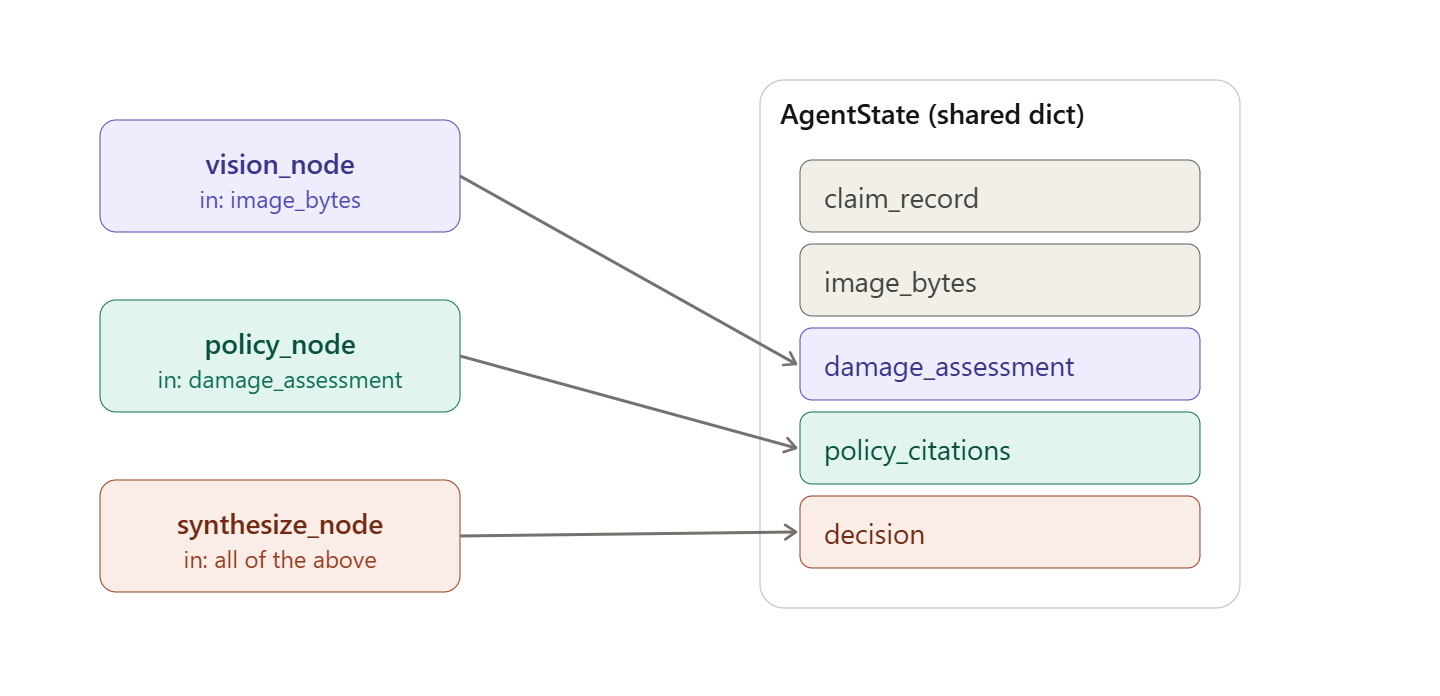

**What you'll do in this step:** wire the pieces together into a **LangGraph** pipeline — a small flowchart of steps (called *nodes*) that pass a shared "state" along.

The flow is a straight line: **vision → policy → synthesize → END**.

1. **vision_node** — looks at the photo (uses the tool from Step 3) and writes a damage assessment into the state.
2. **policy_node** — uses the damage type to pull the relevant policy clauses (uses the tool from Step 4) and writes them into the state.
3. **synthesize_node** — reads *everything* (claim + damage + clauses), runs the fraud check, and writes the final decision.

Five code cells: define the shared state, define nodes 1 & 2, define node 3, build/compile the graph, then draw it.

In [19]:
# --- Shared graph state ---
from typing import TypedDict, Optional, List
# StateGraph = the pipeline builder. END = the marker for 'pipeline finished'.
from langgraph.graph import StateGraph, END

# The SHARED STATE that flows through the pipeline. Think of it as a clipboard:
# each node reads what it needs and writes its result back. total=False means
# fields can be filled in gradually (they don't all need to exist up front).
class AgentState(TypedDict, total=False):
    # Inputs
    claim_record: dict
    image_bytes: bytes
    # Filled by vision_node
    damage_assessment: dict   # DamageAssessment as dict
    # Filled by policy_node
    policy_citations: List[dict]
    # Filled by synthesize_node
    decision: dict

print("✓ AgentState defined (TypedDict)")


✓ AgentState defined (TypedDict)


**What just happened:** you defined `AgentState` — the shared "clipboard" that travels through the pipeline. The comments in the class show the lifecycle clearly: `claim_record` and `image_bytes` go **in**; `damage_assessment` is added by the vision node; `policy_citations` by the policy node; and `decision` by the synthesize node. Each node only adds its piece — it never has to know how the others work.

In [20]:
# --- Node 1: vision_node (uses analyse_damage_photo from Section 3) ---
# NODE 1. Read the image from state, run the Step-3 vision tool, and write the
# damage assessment back. .model_dump() converts the Pydantic object to a plain
# dict so it travels easily through the graph state.
def vision_node(state: AgentState) -> dict:
    result = analyse_damage_photo(state["image_bytes"])
    return {"damage_assessment": result.model_dump()}

# --- Node 2: policy_node (semantic search based on the damage type) ---
# NODE 2. Based on what the vision node SAW, ask the policy four targeted
# questions (coverage, deductible, total-loss rule, required documents).
def policy_node(state: AgentState) -> dict:
    damage = state["damage_assessment"]
    queries = [
        f"Is {damage['damage_type']} covered under own damage?",
        "What deductible applies for a motor own-damage claim?",
        "When is a vehicle declared a total loss?",
        "What documents are required for a claim?",
    ]
    # De-duplicate: the same clause can match several questions; only keep it once.
    seen = set()
    citations = []
    for q in queries:
        for hit in policy_lookup(q, k=2):
            if hit["clause_id"] not in seen:
                seen.add(hit["clause_id"])
                citations.append(hit)
    # Write the unique set of relevant clauses back to the shared state.
    return {"policy_citations": citations}

print("✓ vision_node + policy_node defined")


✓ vision_node + policy_node defined


**What just happened:** you defined the first two nodes. Notice the pattern every LangGraph node follows: **take `state` in, return a small dict of updates**.

- `vision_node` is a thin wrapper around the eyes you already built; `.model_dump()` just converts the structured object into a plain dictionary so it fits in the state.
- `policy_node` is smart about retrieval: it doesn't ask random questions — it uses the *damage type the vision node found* to ask targeted ones (e.g. *"Is total_loss covered under own damage?"*), then de-duplicates the clauses so each appears once.

In [21]:
# --- Node 3: synthesize_node (final coverage decision) ---
from langchain_core.prompts import ChatPromptTemplate

# A cheaper text-only model handles the final reasoning (no image needed here).
# A slight temperature (0.2) allows natural explanations while staying focused.
synthesizer_llm = ChatOpenAI(model="gpt-4.1-mini", temperature=0.2)

# The 'form' for the FINAL answer. Note it captures BOTH the outcome (decision)
# AND the justification (fraud_signal_reason, coverage_clause_ids, reasoning,
# next_steps) -- so every decision is explainable and auditable.
class CoverageDecision(BaseModel):
    decision: str = Field(description="APPROVE | REVIEW | REJECT")
    confidence: float = Field(ge=0.0, le=1.0)
    estimated_repair_inr: int
    claimed_amount_inr: int
    fraud_signal: bool = Field(description=
        "True if photo damage is inconsistent with claimed amount by >30%, "
        "or if other policy FR-001 indicators apply")
    fraud_signal_reason: str
    coverage_clause_ids: List[str] = Field(description=
        "Policy clauses supporting the coverage decision (from policy_citations)")
    reasoning: str = Field(description="2-3 sentence explanation")
    next_steps: str = Field(description="What the adjuster should do next")

# Bind the model to the CoverageDecision form, same structured-output trick as vision.
synth_chain = synthesizer_llm.with_structured_output(CoverageDecision)

# The instructions for the decision-maker. It spells out the APPROVE/REVIEW/REJECT
# rules and the exact fraud-check maths, then leaves {placeholders} that get
# filled with this specific claim, the vision result, and the retrieved clauses.
SYNTH_PROMPT = ChatPromptTemplate.from_template(
    "You are SecureLife's claims adjudication assistant. Make a coverage decision "
    "by cross-checking the visual damage assessment against the customer's claim "
    "and the policy clauses.\n\n"
    "Decision rules:\n"
    "  - APPROVE: damage consistent with claim, total covered amount ≤ sum insured\n"
    "  - REVIEW: any fraud signal triggered, OR ambiguity in damage vs claim\n"
    "  - REJECT: damage type explicitly excluded (see EX-001), or pre-existing damage signs\n\n"
    "Fraud check (per clause FR-001):\n"
    "  - flag if |estimated_repair - claimed_amount| / claimed_amount > 0.30\n"
    "  - flag if estimated_repair > 70% of sum_insured without total-loss declaration\n\n"
    "Claim record:\n{claim_record}\n\n"
    "Vision assessment:\n{damage_assessment}\n\n"
    "Policy clauses retrieved (cite the relevant ones in your decision):\n"
    "{policy_citations}\n"
)

# NODE 3. Fill the prompt's placeholders with everything gathered so far,
# ask the model to decide, and write the structured decision back to state.
def synthesize_node(state: AgentState) -> dict:
    # Inject the live data into the prompt. json.dumps(...) turns the dicts into
    # neat text the model can read.
    rendered = SYNTH_PROMPT.format_messages(
        claim_record=json.dumps(state["claim_record"], indent=2),
        damage_assessment=json.dumps(state["damage_assessment"], indent=2),
        policy_citations="\n".join(
            f"- [{c['clause_id']}] {c['text'][:200]}..." for c in state["policy_citations"]
        ),
    )
    decision = synth_chain.invoke(rendered)
    return {"decision": decision.model_dump()}

print("✓ synthesize_node defined")


✓ synthesize_node defined


**What just happened:** you built the decision-maker. A few things worth noticing:

- It uses a **cheaper text-only model** (`gpt-4.1-mini`) — there's no image at this stage, just reasoning over text, so you don't need the pricier vision model here.
- The `CoverageDecision` form captures **not just the verdict but the *why*** — `fraud_signal_reason`, `coverage_clause_ids`, `reasoning`, and `next_steps`. That's what turns a black-box answer into something an adjuster can trust and act on.
- The fraud rule lives in the **prompt**, stated in plain arithmetic: flag if `|estimated − claimed| / claimed > 0.30`, or if the estimate exceeds 70% of the sum insured without a total-loss declaration. This mirrors policy clause **FR-001**.

In [22]:
# --- Build and compile the graph ---
# Create an empty pipeline that carries our AgentState clipboard.
graph = StateGraph(AgentState)
# Register the three steps as named nodes.
graph.add_node("vision",       vision_node)
graph.add_node("policy",       policy_node)
graph.add_node("synthesize",   synthesize_node)
# Tell the graph where to START.
graph.set_entry_point("vision")
# Connect the steps in order: vision -> policy -> synthesize -> END.
# These edges define the exact route the state takes.
graph.add_edge("vision",     "policy")
graph.add_edge("policy",     "synthesize")
graph.add_edge("synthesize", END)
# Compile the design into a runnable agent. multimodal_agent.invoke({...}) now
# runs the whole pipeline end to end.
multimodal_agent = graph.compile()

print("✓ Graph compiled: vision → policy → synthesize → END")


✓ Graph compiled: vision → policy → synthesize → END


**What just happened:** the three nodes are now wired into a single runnable object, `multimodal_agent`. Building a graph is always the same three moves: **add nodes**, **set the entry point**, **connect with edges**, then **compile**. Because this pipeline is a straight line, the edges simply chain the steps; more advanced agents would add branches or loops here.

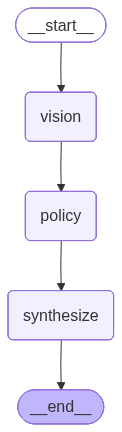

In [23]:
# --- Visualise the graph ---
# Try to draw the graph as a nice diagram; if the drawing dependency is missing,
# fall back to a plain-text (ASCII) version so the cell never hard-fails.
try:
    from IPython.display import Image as IPyImage, display
    display(IPyImage(multimodal_agent.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"(Mermaid render skipped: {e})")
    print(multimodal_agent.get_graph().draw_ascii())


**What just happened:** you rendered the pipeline as a diagram (or a text fallback). You should see the straight line **vision → policy → synthesize → END** — a visual confirmation that the agent is wired exactly as designed.

## Section 6 — Run on Sample Claims

We run the pipeline on all 3 damage scenarios against the same claim record (CLM-2025-0001, claimed amount ₹4,35,957). Expected behaviour:

| Image | Likely vision estimate | Expected decision |
|-------|------------------------|-------------------|
| `front_collision` | Moderate (₹2L-₹5L) | **APPROVE** — consistent with claim |
| `side_scratch` | Low (₹15K-₹40K) | **REVIEW** — large mismatch flags fraud signal (claim ₹4.35L >> ₹40K estimate) |
| `total_loss` | High (₹5L+) | **REVIEW** — likely exceeds 70% IDV threshold (sum insured ₹5L), triggers total-loss assessment |

This is real fraud-detection logic — adjusters apply exactly this reasoning.

**What you'll do in this step:** run the finished agent on all three photos against the **same** claim (CLM-2025-0001, claimed ₹4,35,957) and read the decisions.

This is where the fraud logic shows its value. Watch for the mismatch case: the *side-scratch* photo looks like a small repair, but the customer is claiming ₹4.35L — that gap should trip the fraud signal and push the decision to **REVIEW**, exactly as a human adjuster would react.

In [24]:
# --- Run the pipeline on each sample image ---

# A formatting helper: takes one finished run and prints the vision findings and
# the final decision in a clean, readable block. No logic here, just display.
def pretty_print_decision(label: str, final_state: dict) -> None:
    d = final_state["decision"]
    va = final_state["damage_assessment"]
    print(f"\n{'='*70}")
    print(f"  CLAIM: {final_state['claim_record']['claim_id']}  |  IMAGE: {label}")
    print(f"{'='*70}")
    print(f"  VISION:")
    print(f"    type:                 {va['damage_type']}")
    print(f"    severity:             {va['severity']}/10")
    print(f"    estimated_repair_inr: ₹{va['estimated_repair_inr']:,}")
    print(f"    parts:                {', '.join(va['parts_affected'])}")
    print(f"  DECISION:")
    print(f"    action:               {d['decision']}")
    print(f"    confidence:           {d['confidence']:.2f}")
    print(f"    claimed:              ₹{d['claimed_amount_inr']:,}")
    print(f"    estimated:            ₹{d['estimated_repair_inr']:,}")
    print(f"    fraud signal:         {d['fraud_signal']}  ({d['fraud_signal_reason']})")
    print(f"    cited clauses:        {', '.join(d['coverage_clause_ids'])}")
    print(f"  REASONING:")
    for line in d['reasoning'].split('. '):
        if line.strip():
            print(f"    • {line.strip()}.")
    print(f"  NEXT STEPS:")
    print(f"    {d['next_steps']}")

# Run the FULL agent once per image and collect every result for the summary.
results = {}
# For each scenario, feed the SAME claim_record but a DIFFERENT photo, so we can
# see how the decision changes purely based on what the photo shows.
for damage_type, png_bytes in SAMPLE_IMAGES.items():
    # THE ONE LINE THAT RUNS EVERYTHING: vision -> policy -> synthesize.
    # The inputs are just the claim record and the image bytes.
    final = multimodal_agent.invoke({
        "claim_record": claim_record,
        "image_bytes": png_bytes,
    })
    results[damage_type] = final
    pretty_print_decision(damage_type, final)



  CLAIM: CLM-2025-0001  |  IMAGE: front_collision
  VISION:
    type:                 front_collision
    severity:             5/10
    estimated_repair_inr: ₹150,000
    parts:                front bumper, hood, left headlight
  DECISION:
    action:               APPROVE
    confidence:           0.90
    claimed:              ₹435,957
    estimated:            ₹150,000
    fraud signal:         True  (Claimed amount (₹435,957) differs from estimated repair cost (₹150,000) by more than 30%, triggering fraud indicator FR-001; however, damage is consistent with claim and within sum insured.)
    cited clauses:        OD-001_OwnDamageCoverage, FR-001_FraudIndicators
  REASONING:
    • The vision assessment confirms front-end collision damage consistent with the claim.
    • The estimated repair cost (₹150,000) is well within the sum insured (₹500,000).
    • However, the claimed amount is significantly higher than the estimated repair cost, triggering a fraud signal per clause FR-001.

**What just happened:** you ran the complete agent three times. The single important line is `multimodal_agent.invoke({...})` — that one call fires the whole vision → policy → synthesize pipeline and returns the filled-in state, including the final `decision`.

Read each printed block top to bottom: it shows **what the model saw** (vision), **the verdict** (APPROVE / REVIEW / REJECT), the **fraud signal** with its reason, the **cited clause IDs**, and the **next steps**. Compare these to the gut predictions you made back in Step 2 — especially whether the cheap-looking side-scratch against a ₹4.35L claim got flagged.

In [25]:
# --- Summary table across the 3 scenarios ---
# pandas just makes a tidy comparison TABLE; it adds no decision logic.
import pandas as pd

# Pull the key numbers from each run into one row so all three scenarios sit
# side by side: vision estimate vs claimed amount vs final decision + fraud flag.
rows = []
for damage_type, final in results.items():
    d = final["decision"]
    va = final["damage_assessment"]
    rows.append({
        "scenario":    damage_type,
        "vision_type": va["damage_type"],
        "severity":    va["severity"],
        "est_₹":       f"₹{va['estimated_repair_inr']:,}",
        "claimed_₹":   f"₹{d['claimed_amount_inr']:,}",
        "decision":    d["decision"],
        "fraud":       "FLAG" if d["fraud_signal"] else "—",
        "conf":        f"{d['confidence']:.2f}",
    })

print("\nSUMMARY — 3 scenarios on the SAME claim (CLM-2025-0001, claimed ₹4,35,957):\n")
print(pd.DataFrame(rows).to_string(index=False))



SUMMARY — 3 scenarios on the SAME claim (CLM-2025-0001, claimed ₹4,35,957):

       scenario        vision_type  severity    est_₹ claimed_₹ decision fraud conf
front_collision    front_collision         5 ₹150,000  ₹435,957  APPROVE  FLAG 0.90
   side_scratch side_panel_scratch         3  ₹15,000  ₹435,957  APPROVE  FLAG 0.90
     total_loss         total_loss        10 ₹600,000  ₹435,957   REVIEW  FLAG 0.95


**What just happened:** you collapsed the three runs into one comparison table. Read it left to right: the **estimated** repair (from the photo) next to the **claimed** amount (from the customer), then the **decision** and **fraud** flag. Seeing all three scenarios in one view makes the agent's logic obvious — similar amounts approve, mismatched amounts get flagged for review. That single table is essentially the agent's value proposition in one screen.

## Section 7 — Production Path + Recap

### Production path: from this notebook to real claims at scale

| Notebook today | Real production deployment |
|----------------|---------------------------|
| Synthetic damage images (Pillow) | Real customer photos uploaded via the SecureLife mobile app → S3 bucket |
| `analyse_damage_photo(bytes)` | Lambda triggered on S3 upload, calls GPT-4o, writes result to DynamoDB |
| Inline policy text | RAG over the **full policy registry** (every SecureLife product variant) |
| Mock or DB-loaded claim | Real claim from the SecureLife claims DB via the **MCP server** (Module 6) |
| Single-shot decision | Decision feeds into the **5-node LangGraph review pipeline** (Lab 24 v2) → human adjuster gets a pre-filled recommendation |

The agent code itself doesn't change — only the I/O layer.

### Recap — what you built

- **Vision-grounded claims agent**: GPT-4o looks at vehicle damage and produces structured assessments
- **Text-grounded RAG**: FAISS vector store over the SecureLife Motor Comprehensive policy
- **Multimodal LangGraph**: 3 nodes that compose vision + RAG + DB record into one coverage decision
- **Real fraud heuristic**: cross-check photo damage estimate against claimed amount; flag mismatches per policy `FR-001`
- **Structured output everywhere**: Pydantic schemas for both vision assessment and final decision

### Key takeaways

1. **Multimodal in LangChain is just another content block.** No new framework, no separate API — `image_url` slots into the same message you'd send with text.
2. **GPT-4o + structured output** = adjuster-ready JSON, not free-form descriptions. The `with_structured_output(Schema)` pattern is the multiplier.
3. **RAG + vision + structured DB record** is the production claims pattern. Each modality answers a different part of "should we pay this claim?"
4. **The fraud signal is a 4-line check** — `|est - claimed| / claimed > 0.30`. Most production fraud heuristics are this simple; the value is in **applying** them consistently.

### Where this fits in the SecureLife arc

| Module | Capability you added |
|--------|---------------------|
| Module 6 (Labs 21-24v2) | Guardrails, observability, **MCP server with 8 SQL tools**, multi-agent review graph with persistence |
| Module 6 (Lab 25 + securelife_client_app) | Production MCP server-client, FastAPI service, Chainlit chat UI |
| Module 7 (Lab 27) | Comparison framework: same compliance pipeline in **Google ADK** vs LangGraph |
| **Module 7 (Lab 28 — this lab)** | **Multimodal vision + text RAG** layered on top of the SecureLife agent |

**SecureLife is now a complete agentic insurance system** — structured DB, MCP layer, REST/chat/CLI consumers, multi-step review, multimodal intake, and a production deployment path.

**End of Module 7 lab series.**